# Advanced Transport Phenomena

## Practical session 6 - Reactive species transport: operator splitting

from Alberto Cuoci and Adrien Guillonneau

A three-species reaction chain A -> B -> C, transported by advection and diffusion along a 1D domain. This session solves it two ways: fully explicit, and operator splitting, which decouples the stiff local chemistry from the spatial transport. A third approach, treating the reaction term implicitly inside the same linear system as the transport, is the subject of the next session.

## Notes for this practical

This practical introduces `solve_ivp`'s stiff solvers. In the multicomponent diffusion practical, `solve_ivp` was used with its default method, RK45, suited to smooth, non-stiff systems. The local reaction chemistry here is a different kind of problem: a very wide spread of time scales (fast consumption of A, slower formation of C), which is the definition of a stiff system. 

For a stiff system, RK45 would need an impractically small step to stay stable, even though the solution itself is not changing that fast everywhere. The fix is the same `solve_ivp` call with `method="BDF"` instead, an implicit, variable-order method built specifically for stiff problems (MATLAB's `ode15s` is the same family). `method="Radau"` is a common alternative, also implicit.

## 1. Case description

A 1D domain of length $L$, with constant velocity $u$ and diffusivity $D$, carries three species undergoing a consecutive reaction chain:

$$
A \xrightarrow{r_1} B \xrightarrow{r_2} C
$$

with rates $r_1 = k_1 C_A^2$ (second order in A) and $r_2 = k_2 C_B$ (first order in B). Each species obeys the same advection-diffusion-reaction equation, coupled only through the reaction terms:

$$
\frac{\partial C_A}{\partial t} + u\frac{\partial C_A}{\partial x} = D\frac{\partial^2 C_A}{\partial x^2} - k_1 C_A^2
$$
$$
\frac{\partial C_B}{\partial t} + u\frac{\partial C_B}{\partial x} = D\frac{\partial^2 C_B}{\partial x^2} + k_1 C_A^2 - k_2 C_B
$$
$$
\frac{\partial C_C}{\partial t} + u\frac{\partial C_C}{\partial x} = D\frac{\partial^2 C_C}{\partial x^2} + k_2 C_B
$$

At the inlet ($x=0$), $C_A=C_{A,in}=1$ kmol/m$^3$, $C_B=C_C=0$ (Dirichlet). At the outlet, zero gradient. The system starts empty and is integrated forward in time until it reaches steady state.

This is the first practical where several species are transported on the same spatial grid at once, and the only thing that couples them is the reaction term: without it, $C_A$, $C_B$, $C_C$ would just be three independent copies of the same advection-diffusion problem from Practical 1.

## 2. Numerical setup

Three independent stability limits have to be respected for an explicit scheme: one for the combined advection-diffusion operator, one for diffusion alone, and one for the reaction term, which is a stiff nonlinear system. Its stability limit comes from the eigenvalues of the reaction Jacobian, $\tau_C = 1/\max|\mu_i|$

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import time

L = 2.0          # domain length [m]
tau = 5.0        # final (physical) time [s]
ncells = 200     # number of grid cells

u = 1.0          # velocity [m/s]
D = 1.0e-2       # diffusivity [m2/s]

#Rates
k1 = 1000.0        # rate constant for A -> B [m3/kmol/s]
k2 = 1.0         # rate constant for B -> C [1/s]

sigma = 0.5      # safety factor on the time step

#Initial conditions
CAin = 1.0       # inlet concentration of A [kmol/m3]
CBin = 0.0
CCin = 0.0

h = L / ncells #spatial step

# stability limits
dt_adv_diff = 2 * D / u**2 #advection-diffusion
dt_diff = h**2 / (2 * D) #diffusion 
J = np.array([[-2*k1*CAin, 0.0,  0.0],
              [ 2*k1*CAin, -k2,  0.0],
              [ 0.0,        k2,  0.0]])
eigs = np.linalg.eigvals(J)
dt_react = 1.0 / np.max(np.abs(eigs))

dt = sigma * min(dt_adv_diff, dt_diff, dt_react)
nsteps = int(np.ceil(tau / dt))

print(f"Maximum time step for advection-diffusion: {dt_adv_diff:.5f} s")
print(f"Maximum time step for diffusion alone:     {dt_diff:.5f} s")
print(f"Maximum time step for the reactions:       {dt_react:.5f} s")
print(f"Selected time step:                        {dt:.5f} s  ({nsteps} steps)")

Maximum time step for advection-diffusion: 0.02000 s
Maximum time step for diffusion alone:     0.00500 s
Maximum time step for the reactions:       0.00050 s
Selected time step:                        0.00025 s  (20000 steps)


## 3. Explicit method

A quick baseline, built exactly like the explicit scheme from Practical 1, just applied to three coupled species at once. All three stability limits above have to be respected simultaneously by the same, single time step, including the reaction one, even though transport and reaction are physically very different processes.

In [2]:
def transport_step(C, S, u, D, dt, h, ncells):
    Co = C.copy()
    Cnew = C.copy()
    for i in range(1, ncells + 1):
        adv = u * (Co[i+1] - Co[i-1]) / (2*h)
        diff = D * (Co[i+1] - 2*Co[i] + Co[i-1]) / h**2
        Cnew[i] = Co[i] + dt * (-adv + diff + S[i])
    return Cnew


def apply_bc(C, Cin):
    C[0] = 2*Cin - C[1]   # inlet, Dirichlet
    C[-1] = C[-2]          # outlet, zero gradient
    return C


def reaction_rates(CA, CB, CC, k1, k2):
    RA = -k1 * CA**2
    RB =  k1 * CA**2 - k2 * CB
    RC =  k2 * CB
    return RA, RB, RC


def explicit_step(CA, CB, CC, u, D, dt, h, ncells, k1, k2):
    RA, RB, RC = reaction_rates(CA, CB, CC, k1, k2)
    CA = transport_step(CA, RA, u, D, dt, h, ncells)
    CB = transport_step(CB, RB, u, D, dt, h, ncells)
    CC = transport_step(CC, RC, u, D, dt, h, ncells)
    return CA, CB, CC

## 4. Operator splitting

Instead of forcing transport and reaction to share one time step, operator splitting treats them one after another within the same step: first transport alone (no reaction), then reaction alone, locally, in every cell, with no transport at all. Each sub-step only has to be stable for the physics it actually represents.

The reaction sub-step is a genuinely different kind of problem from anything solved by hand so far: three coupled, nonlinear, stiff ODEs, local to a single cell, with no spatial coupling at all. This is exactly the situation `solve_ivp(method="BDF")` is built for.

In [15]:
def reaction_rhs(t, y, k1, k2):
    CA, CB, CC = y
    dCA_dt = -k1 * CA**2
    dCB_dt =  k1 * CA**2 - k2 * CB
    dCC_dt =  k2 * CB
    return [dCA_dt, dCB_dt, dCC_dt]


def operator_splitting_step(CA, CB, CC, u, D, dt, h, ncells, k1, k2):
    ZERO = np.zeros_like(CA)
    CA = transport_step(CA, ZERO, u, D, dt, h, ncells)
    CB = transport_step(CB, ZERO, u, D, dt, h, ncells)
    CC = transport_step(CC, ZERO, u, D, dt, h, ncells)

    for i in range(1, ncells + 1):
        sol = solve_ivp(reaction_rhs, [0, dt], [CA[i], CB[i], CC[i]],
                         method="Radau", args=(k1, k2))
        CA[i], CB[i], CC[i] = sol.y[:, -1]

    return CA, CB, CC

Three implementation details worth noting in the loop above: the range is `range(1, ncells + 1)`, covering every interior cell without silently skipping the last one; `args=(k1, k2)` is passed explicitly, since `reaction_rhs` needs them and they are not global; and the final state is read off as `sol.y[:, -1]` (the state at the end of the local integration), not `sol.y[:, 0]` (the initial condition it started from).

## 5. Bringing it together

### 5.1 Quick look, on a coarse grid

Running the full-resolution case (200 cells, a couple thousand steps, each with an implicit per-cell solve for every one of those cells) takes a while. A much coarser grid gives a fast, rough preview, useful to see the shape of the solution before committing to the real run below.

In [16]:
def run(method, ncells_run, dt_run, nsteps_run):
    ZERO = np.zeros(ncells_run + 2)
    CA, CB, CC = ZERO.copy(), ZERO.copy(), ZERO.copy()
    h_run = L / ncells_run
    for _ in range(nsteps_run):
        CA = apply_bc(CA, CAin)
        CB = apply_bc(CB, CBin)
        CC = apply_bc(CC, CCin)
        if method == "explicit":
            CA, CB, CC = explicit_step(CA, CB, CC, u, D, dt_run, h_run, ncells_run, k1, k2)
        elif method == "opsp":
            CA, CB, CC = operator_splitting_step(CA, CB, CC, u, D, dt_run, h_run, ncells_run, k1, k2)
    return CA, CB, CC


def cell_to_face(C, ncells_run):
    Cface = np.zeros(ncells_run + 1)
    for i in range(ncells_run + 1):
        Cface[i] = 0.5 * (C[i+1] + C[i])
    return Cface


ncells_q = 50
h_q = L / ncells_q
dt_adv_diff_q = 2 * D / u**2
dt_diff_q = h_q**2 / (2 * D)
dt_q =  sigma * min(dt_adv_diff_q, dt_diff_q, dt_react)
print(dt_q)
nsteps_q = int(np.ceil(tau / dt_q))
x_q = np.linspace(0, L, ncells_q + 1)

dt_opsp_q = sigma * min(dt_adv_diff_q, dt_diff_q)
print(dt_opsp_q)
nsteps_opsp_q = int(np.ceil(tau / dt_opsp_q))

t0 = time.time()
CA_exp_q, CB_exp_q, CC_exp_q = run("explicit", ncells_q, dt_q, nsteps_q)
print(f"explicit, coarse grid: {time.time()-t0:.2f} s")

t0 = time.time()
CA_ops_q, CB_ops_q, CC_ops_q = run("opsp", ncells_q, dt_opsp_q, nsteps_opsp_q)
print(f"operator splitting, coarse grid: {time.time()-t0:.2f} s")

0.00025
0.01
explicit, coarse grid: 5.19 s
operator splitting, coarse grid: 21.91 s


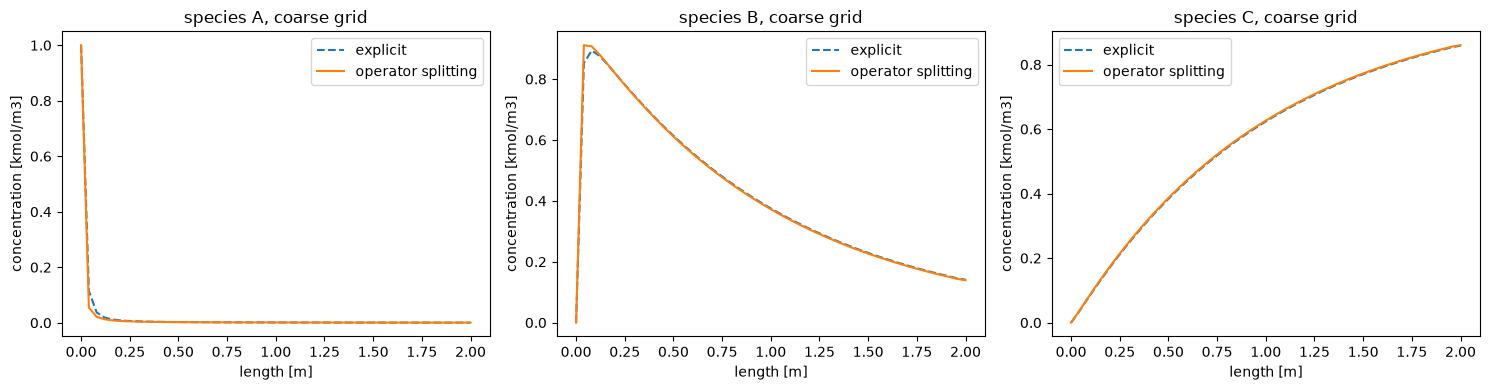

In [17]:
#PLOTTING#
CAp_exp_q = cell_to_face(CA_exp_q, ncells_q)
CBp_exp_q = cell_to_face(CB_exp_q, ncells_q)
CCp_exp_q = cell_to_face(CC_exp_q, ncells_q)
CAp_ops_q = cell_to_face(CA_ops_q, ncells_q)
CBp_ops_q = cell_to_face(CB_ops_q, ncells_q)
CCp_ops_q = cell_to_face(CC_ops_q, ncells_q)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
labels = ["A", "B", "C"]
exp_q = [CAp_exp_q, CBp_exp_q, CCp_exp_q]
ops_q = [CAp_ops_q, CBp_ops_q, CCp_ops_q]
for k in range(3):
    axes[k].plot(x_q, exp_q[k], "--", label="explicit")
    axes[k].plot(x_q, ops_q[k], label="operator splitting")
    axes[k].set_xlabel("length [m]")
    axes[k].set_ylabel("concentration [kmol/m3]")
    axes[k].set_title(f"species {labels[k]}, coarse grid")
    axes[k].legend()
plt.tight_layout()
plt.show()

### 5.2 Full resolution, the real comparison

The actual case, run at the full 200 cells and the step count from the setup above. This cell is slower (the operator-split run calls `solve_ivp` once per cell, per step), start it and let it run.

In [6]:
x = np.linspace(0, L, ncells + 1)

t0 = time.time()
CA_exp, CB_exp, CC_exp = run("explicit", ncells, dt, nsteps)
t_exp = time.time() - t0
print(f"explicit, full resolution: {t_exp:.1f} s")

t0 = time.time()
CA_ops, CB_ops, CC_ops = run("opsp", ncells, dt, nsteps)
t_ops = time.time() - t0
print(f"operator splitting, full resolution: {t_ops:.1f} s")

explicit, full resolution: 2.3 s


KeyboardInterrupt: 

In [ ]:
CAp_exp = cell_to_face(CA_exp, ncells)
CBp_exp = cell_to_face(CB_exp, ncells)
CCp_exp = cell_to_face(CC_exp, ncells)
CAp_ops = cell_to_face(CA_ops, ncells)
CBp_ops = cell_to_face(CB_ops, ncells)
CCp_ops = cell_to_face(CC_ops, ncells)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
exp_f = [CAp_exp, CBp_exp, CCp_exp]
ops_f = [CAp_ops, CBp_ops, CCp_ops]
for k in range(3):
    axes[k].plot(x, exp_f[k], "--", label="explicit")
    axes[k].plot(x, ops_f[k], label="operator splitting")
    axes[k].set_xlabel("length [m]")
    axes[k].set_ylabel("concentration [kmol/m3]")
    axes[k].set_title(f"species {labels[k]}, full resolution")
    axes[k].legend()
plt.tight_layout()
plt.show()

print(f"explicit:            {t_exp:.1f} s total, {nsteps} steps")
print(f"operator splitting:  {t_ops:.1f} s total, {nsteps} steps, {ncells} implicit solves per step")

Both methods should land on essentially the same steady profile, they are two different ways of solving the same equations. The real difference is in the cost breakdown: explicit spends its time on many cheap steps, forced small by whichever constraint binds tightest; operator splitting spends its time on far fewer, more expensive steps, since every one of them includes an implicit solve in every cell.

## Exercises

1. Increase `k1` (for example to 1000) and recompute `dt_react`. Confirm it becomes the tightest of the three constraints, then estimate how many steps explicit would need at the resulting `dt` to reach `tau`, compared to operator splitting, whose step size no longer depends on `k1` at all.
2. Deliberately run the explicit method with a `dt` larger than `dt_react` and see what happens to `CA`.
3. At full resolution, compute the maximum difference between `CA_exp` and `CA_ops` at steady state. Is it roughly the size you would expect from a first-order explicit scheme on the transport side?
4. Swap `method="BDF"` for `method="Radau"` in the reaction sub-step and check whether the result or the runtime changes noticeably.